### Selection (pre-registered rule) and how flat the top is

Each arm against B\*: the geometric-mean ratio of final regrets (paired over tasks, 95% bootstrap CI); gain = 1 − ratio in the table.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.bo import arm_table, final, paired_gain, regrets, select_portfolio

# the pre-registered grid, and its extension past the grid edge (log §4): same tasks, same nuisance streams
SNAPSHOTS = ["results/static_tune/pilot_20261021-150441", "results/static_tune/pilot_20261021-151907"]
snaps = [load_snapshot(s) for s in SNAPSHOTS]
for snap in snaps:
    show_header(snap)

## How it was run

```bash
just sweep detached pilot experiment=static_tune task.d=2,4,6
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261021-150441` |
| commit | `f23437027b1a` (tag `sweep/static_tune/pilot_20261021-150441`) |
| backend / host | detached / ulysses |
| ran | 2026-10-21T15:04:42 → 2026-10-21T15:17:51 |
| members | 3: 3 done |
| compute | 13.1 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/static_tune.yaml`):

```yaml
# @package _global_
# Which static acquisition arms are competitive with pfn_large, per d? Selects the base arm B* and the
# switching portfolio on the tuning split (0); the switching experiment re-measures them on split 1.
# Sweep: task.d=2,4,6
defaults:
  - override /task: bo

task:
  split: 0
  n_tasks: 200
  method: static
  arms: [ei, ei0.01, ei0.05, pi0.01, pi0.05, pi0.1, ucb0.8, ucb0.9, ucb0.95, ucb0.99, mean, mes, es]
```

**Varying** (3 configurations):

| task.d |
|---|
| 2 |
| 4 |
| 6 |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ei", "ei0.01", "ei0.05", "pi0.01", "pi0.05", "pi0.1", "ucb0.8", "ucb0.9",
    "ucb0.95", "ucb0.99", "mean", "mes", "es"]'
  base: ei
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cuda
  eps: 0.0001
  method: static
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 200
  name: bo
  null_k: 6
  null_reference: false
  pfn: pfn_large
  random_search: true
  segment_per_d: 2
  split: 0
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

## How it was run

```bash
just sweep detached pilot experiment=static_tune task.d=2,4,6 'task.arms=[ucb0.995,ucb0.999,pi,pi0.001]' task.random_search=false
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261021-151907` |
| commit | `f23437027b1a` (tag `sweep/static_tune/pilot_20261021-151907`) |
| backend / host | detached / ulysses |
| ran | 2026-10-21T15:19:09 → 2026-10-21T15:24:57 |
| members | 3: 3 done |
| compute | 5.8 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/static_tune.yaml`):

```yaml
# @package _global_
# Which static acquisition arms are competitive with pfn_large, per d? Selects the base arm B* and the
# switching portfolio on the tuning split (0); the switching experiment re-measures them on split 1.
# Sweep: task.d=2,4,6
defaults:
  - override /task: bo

task:
  split: 0
  n_tasks: 200
  method: static
  arms: [ei, ei0.01, ei0.05, pi0.01, pi0.05, pi0.1, ucb0.8, ucb0.9, ucb0.95, ucb0.99, mean, mes, es]
```

**Varying** (3 configurations):

| task.d |
|---|
| 2 |
| 4 |
| 6 |

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  alpha: alpha_pes_large
  arms: '["ucb0.995", "ucb0.999", "pi", "pi0.001"]'
  base: ei
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 512
  device: cuda
  eps: 0.0001
  method: static
  n_init_per_d: 2
  n_rollouts: 8
  n_tasks: 200
  name: bo
  null_k: 6
  null_reference: false
  pfn: pfn_large
  random_search: false
  segment_per_d: 2
  split: 0
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  task_offset: 0
  tf32: false
```

## Results

Regrets are measured against one f\* per task (the lowest value any arm or the dense search found).

In [ ]:
def keyed(snap, name):
    """A snapshot table with member ids made unique across sweeps."""
    return snap.table(name).assign(member=lambda x: snap.manifest["id"] + ":" + x.member.astype(str))

best = pd.concat([keyed(s, "best") for s in snaps], ignore_index=True)
fstar = pd.concat([keyed(s, "fstar") for s in snaps], ignore_index=True)
d_of = pd.concat([s.runs.assign(member=s.manifest["id"] + ":" + s.runs.member.astype(str)).set_index("member")["task.d"] for s in snaps])
reg = regrets(best, fstar, d_of)
fin = final(reg)
table = arm_table(fin)
table.pivot(index="arm", columns="d", values="mean_log_regret").sort_values(6).round(3)

d,2,4,6
arm,,,
ucb0.995,-3.604,-3.266,-3.139
ucb0.999,-3.434,-3.046,-3.094
ucb0.99,-3.605,-3.265,-3.092
mes,-3.654,-3.222,-3.038
ucb0.95,-3.581,-3.123,-2.905
ei,-3.550,-2.999,-2.766
pi0.01,-3.345,-2.939,-2.757
ucb0.9,-3.452,-2.980,-2.738
ei0.01,-3.295,-2.871,-2.698


### Regret curves

Geometric mean of (regret + 1e-4) over tasks, per arm; random search dashed.

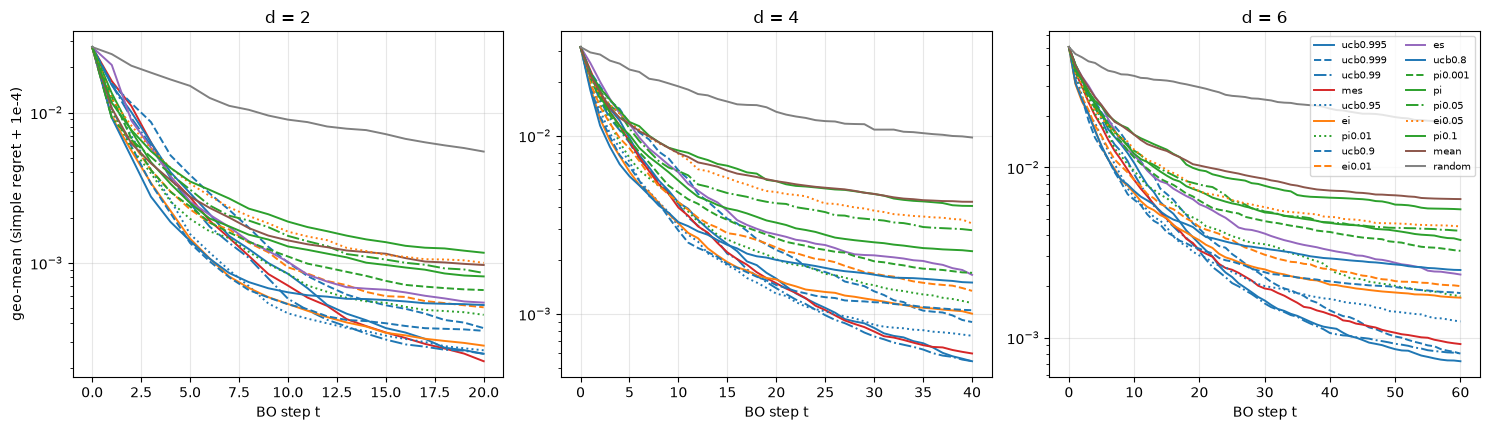

In [ ]:
FAMILY_COLOR = {"ucb": "C0", "ei": "C1", "pi": "C2", "mes": "C3", "es": "C4", "mean": "C5", "random": "gray"}
def style(arm):
    fam = arm.rstrip("0123456789.")
    rank = sorted(a for a in table.arm.unique() if a.rstrip("0123456789.") == fam).index(arm)
    return dict(color=FAMILY_COLOR[fam], ls=["-", "--", ":", "-."][rank % 4], lw=1.4)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (d, g) in zip(axes, reg.groupby("d"), strict=True):
    curves = g.groupby(["arm", "t"]).log_regret.mean().unstack(0)
    for arm in table.loc[table.d == d, "arm"]:
        ax.plot(curves.index, 10 ** curves[arm], label=arm, **style(arm))
    ax.set_yscale("log"); ax.set_title(f"d = {d}"); ax.set_xlabel("BO step t"); ax.grid(alpha=0.3)
axes[0].set_ylabel("geo-mean (simple regret + 1e-4)")
axes[-1].legend(fontsize=7, ncol=2, loc="upper right")
fig.tight_layout()

### Selection (pre-registered rule) and how flat the top is

Each arm against B\*: the geometric-mean ratio of final regrets (paired over tasks, 95% bootstrap CI); gain = 1 − ratio in the table.

In [ ]:
selection = {d: select_portfolio(table, d) for d in sorted(fin.d.unique())}
for d, sel in selection.items():
    print(f"d={d}: B* = {sel['base']:8s} family best = {sel['family_best']}  portfolio = {sel['portfolio']}")
gains = pd.DataFrame([paired_gain(fin, d, a, sel["base"], n_boot=4000)
                      for d, sel in selection.items() for a in sorted(fin.arm.unique()) if a != sel["base"]])
gains.pivot(index="a", columns="d", values="gain").round(3)

d=2: B* = mes      family best = {'ei': 'ei', 'pi': 'pi0.01', 'ucb': 'ucb0.99'}  portfolio = ['mes', 'ei', 'pi0.01', 'ucb0.99', 'es', 'mean']
d=4: B* = ucb0.995 family best = {'ei': 'ei', 'pi': 'pi0.01', 'ucb': 'ucb0.995'}  portfolio = ['ucb0.995', 'ei', 'pi0.01', 'mes', 'es', 'mean']
d=6: B* = ucb0.995 family best = {'ei': 'ei', 'pi': 'pi0.01', 'ucb': 'ucb0.995'}  portfolio = ['ucb0.995', 'ei', 'pi0.01', 'mes', 'es', 'mean']


d,2,4,6
a,,,
ei,-0.270,-0.849,-1.363
ei0.01,-1.284,-1.482,-1.763
ei0.05,-3.512,-4.927,-5.199
es,-1.454,-2.052,-2.233
mean,-3.365,-6.843,-7.971
mes,NaN,-0.105,-0.262
pi,-2.665,-3.144,-4.160
pi0.001,-1.974,-2.134,-3.453
pi0.01,-1.036,-1.120,-1.408


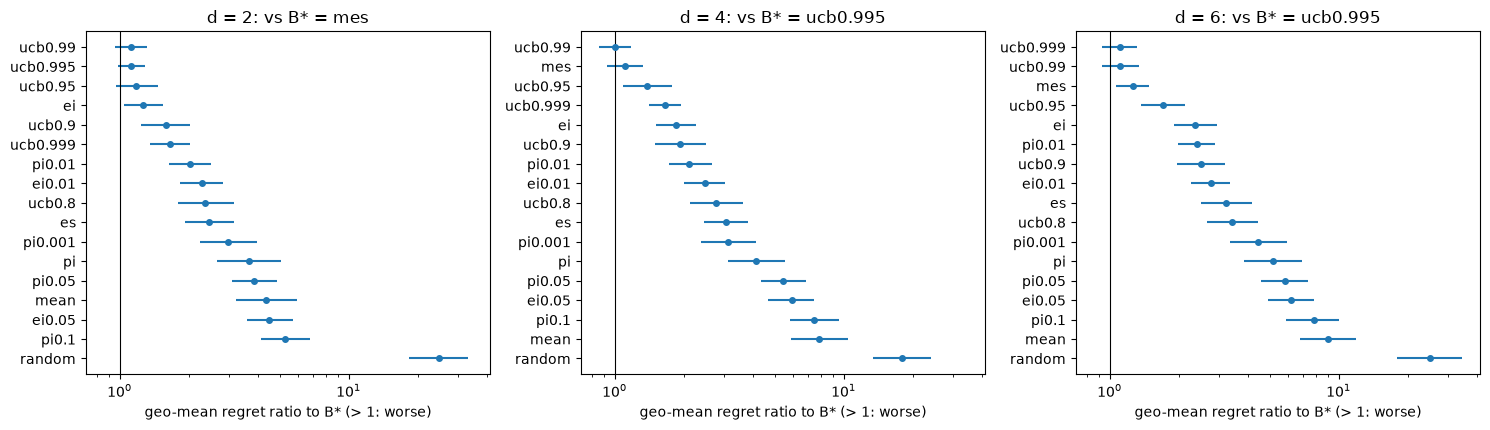

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True)
for ax, (d, g) in zip(axes, gains.groupby("d"), strict=True):
    g = g.sort_values("gain")
    ratio, lo, hi = 1 - g.gain, 1 - g.gain_hi, 1 - g.gain_lo
    ax.errorbar(ratio, range(len(g)), xerr=[ratio - lo, hi - ratio], fmt="o", ms=4)
    ax.set_yticks(range(len(g)), g.a); ax.axvline(1, c="k", lw=0.8); ax.set_xscale("log")
    ax.set_title(f"d = {d}: vs B* = {selection[d]['base']}"); ax.set_xlabel("geo-mean regret ratio to B* (> 1: worse)")
fig.tight_layout()

## Observations

- **Every arm beats random search by a wide margin**: random's final regret is 17–24× that of B\* at every d, so no arm is broken.
- **Exploration wins, increasingly with d.** The top arms are high-quantile UCB (0.99–0.995) and MES. EI is 1.3× B\*'s regret at d = 2, 1.8× at d = 4 and 2.4× at d = 6, which is the under-exploration the predecessor saw. Exploitative settings (`mean`, large PI/EI margins) are 4–9× worse. `es` (the alpha-PFN) is 2.5–3.2× worse than B\*. As an arm on its own it is not competitive here.
- **The first grid was too narrow.** `ucb0.99` was the most exploratory UCB in it and was best at d = 4, 6. The extension (sweep `pilot_20261021-151907`, same tasks and nuisance) puts the UCB optimum inside the grid: 0.995 beats both 0.99 and 0.999 at d = 4, and ties 0.99 at d = 6 while 0.999 falls off at d = 2, 4. The PI optimum stays at margin 0.01: `pi` and `pi0.001` are worse.
- **The top is flat.** The runners-up are statistically indistinguishable from B\* at every d: `ucb0.99` / `ucb0.995` at d = 2, `ucb0.99` and `mes` at d = 4, `ucb0.99` / `ucb0.999` at d = 6. Their ratio CIs include 1. A switching rule among *these* arms has little room. Any gain must come from using an otherwise worse arm at the right moment.
- **The variance is large.** The per-task sd of the log10 regret ratio between two good arms is ≈ 0.5–0.6. This is what sized the switching experiment (its notebook, revision note).
- At d = 2 the curves cross more than at d = 4, 6: rankings early in the run differ from rankings at the horizon, so a budget-dependent choice could matter most there.

Selection (rule applied to both sweeps together):

| d | B\* | portfolio (B\* first) |
|---|---|---|
| 2 | `mes` | mes, ei, pi0.01, ucb0.99, es, mean |
| 4 | `ucb0.995` | ucb0.995, ei, pi0.01, mes, es, mean |
| 6 | `ucb0.995` | ucb0.995, ei, pi0.01, mes, es, mean |


## Verdict

**GO (selection made):** all 3 + 3 members DONE, every arm ran on all 200 tasks per d, and the rule picked B\* and the portfolio above. These numbers are tuning-split numbers and carry the best-of-17 selection effect. The held-out values of B\* and the other arms come from `switching` on fresh tasks.